# MERSCOPE Tongue — Cross-Modal Benchmark Against Existing Alignment Methods (Fig 4g–i, S12, S13)

The cross-modal (protein–RNA) benchmark of the SAME paper on near-serial sections of human dorsal tongue: a
PhenoCycler-Fusion (PCF) protein section (query, 4,671 cells) aligned to a MERSCOPE RNA section (template, 3,608
cells). Existing methods were adapted to protein–RNA input following their documentation (Methods), all starting from
the same image-based initial alignment.

| Panel | Content |
|---|---|
| Fig 4g | Cell type matches per method |
| Fig 4h | Cell neighborhood matches per method |
| Fig 4i | Method summary: required inputs and change over the baseline |
| Fig S12 | Cell neighborhoods on the template and query sections |
| Fig S13 | Predicted RNA expression of marker genes per PCF cell type after each alignment |

The SAME run itself (Fig 4a–f) is in [`examples/tongue/reproduce_figures.ipynb`](../../examples/tongue/reproduce_figures.ipynb).
The notebooks that ran each competing method are in [`methods/`](methods/) (see [`../README.md`](../README.md)).
STIM is not included: it failed in the cross-modal setting.

## Evaluation

Each method returns positions for the query cells in the template's frame; SAME instead assigns each matched query cell
to a template cell. Every method is scored in the same way:

1. **One-to-one assignment.** Aligned query cells are assigned to template cells with the Hungarian algorithm on
   Euclidean distance; pairs more than 500 registration units apart are not allowed and are dropped.
2. **Cell type (CT) matches**: percentage of assigned query–template pairs whose cell types agree (five cell types,
   annotated separately in each modality).
3. **Cell neighborhood (CN) matches**: the same score with cell-neighborhood labels instead of cell types. A cell's
   neighborhood is the cell-type composition of its five nearest neighbours (scimap `spatial_count`, kNN = 6
   including the cell itself), clustered into four neighborhoods by one k-means model fitted on both sections.
4. **Predicted expression (Fig S13).** Each assigned PCF cell receives the RNA profile of its template cell; the
   heatmaps show the mean of marker genes per PCF cell type, scaled to 0–1 per gene.

The baseline is the initial image-based alignment.

### Requirements

Download from the SAME Zenodo record, <https://zenodo.org/records/19056915> (latest version):

* `SAME_benchmarks_data.zip` (aligned outputs of every method): unzip inside `benchmarks/`, which creates
  `benchmarks/tongue/data/`;
* `SAME_data.zip` (SAME inputs, see `examples/README.md`): unzip inside `examples/`; Fig S13 uses
  `examples/tongue/data/merSubAD.h5ad` (RNA counts) and `pcfSubAD.h5ad` (PCF cell types).

Run this notebook from `benchmarks/tongue/`. SAME itself is not needed. Versions used:

```bash
pip install "scanpy==1.11.4" "anndata==0.10.9" "numpy==1.26.4" "scipy==1.16.2" "pandas==2.3.2" \
    "scikit-learn==1.9.1" "matplotlib==3.10.6" "jinja2==3.1.6"
```

Runtime: a few minutes on a laptop (nine 4,671 × 3,608 assignment problems).

## Setup

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy
import sklearn
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.neighbors import BallTree

warnings.filterwarnings('ignore', category=FutureWarning)

NOTEBOOK_DIR = Path('.').resolve()
DATA_DIR = NOTEBOOK_DIR / 'data'
EXPR_DIR = NOTEBOOK_DIR.parents[1] / 'examples' / 'tongue' / 'data'  # from SAME_data.zip
FIG_DIR = NOTEBOOK_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'],
                     'svg.fonttype': 'none', 'pdf.fonttype': 42, 'font.size': 8})

print(f'scanpy {sc.__version__} | anndata {ad.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | '
      f'pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

scanpy 1.11.4 | anndata 0.10.9 | numpy 1.26.4 | scipy 1.16.2 | pandas 2.3.2 | scikit-learn 1.9.1


In [2]:
MAX_DIST = 500       # largest query-template distance allowed in the assignment (registration units)
KNN = 6              # neighbours per cell for the neighborhood composition (including the cell itself)
N_NEIGHBORHOODS = 4
SEED = 2025

# file tag, and whether the method needs expression / cell types as input in the protein-RNA setting
METHODS = pd.DataFrame([
    ('Baseline',  'input',     False, False),
    ('SAME',      'SAME',      False, True),
    ('SPACEL',    'SPACEL',    False, True),
    ('STAlign',   'STAlign',   False, False),  # cell density only: expression input did not improve on the baseline
    ('GPSA',      'GPSA',      True,  False),
    ('STAligner', 'STAligner', True,  True),
    ('ST-GEARS',  'STGEARS',   True,  True),
    ('CAST',      'CAST',      True,  False),
    ('PASTE2',    'PASTE2',    True,  False),
], columns=['method', 'tag', 'expression', 'cell_types']).set_index('method')

## 1. Input sections

`query_input_Prot_tongue.h5ad` (PCF) and `ref_input_RNA_tongue.h5ad` (MERSCOPE) hold both sections after the
initial image-based alignment (`obsm['X_spatial']`; also `New_X`, `New_Y`) with each cell's type. PCF cells are
identified by their `Object ID`.

In [3]:
query_in = ad.read_h5ad(DATA_DIR / 'query_input_Prot_tongue.h5ad')
template_in = ad.read_h5ad(DATA_DIR / 'ref_input_RNA_tongue.h5ad')
query_in.obs_names = query_in.obs['Object ID'].astype(str).to_numpy()
template_in.obs_names = template_in.obs_names.astype(str)
print(f'query (PCF): {query_in.n_obs} cells | template (MERSCOPE): {template_in.n_obs} cells | '
      f'cell types: {sorted(template_in.obs["CellType"].astype(str).unique())}')

query (PCF): 4671 cells | template (MERSCOPE): 3608 cells | cell types: ['Endothelial cells', 'Epithelial cells', 'Fibroblasts', 'Lymphoid cells', 'Myeloid cells']


## 2. Cell neighborhoods

Computed on the initial registration (`New_X`, `New_Y`). This reimplements scimap's `spatial_count` with the same
neighbour search (scikit-learn `BallTree`) and gives the labels used in the paper.

In [4]:
def neighborhood_composition(xy, cell_type, categories, knn=KNN):
    """Fraction of each cell type among a cell's knn - 1 nearest neighbours
    (scimap `sm.tl.spatial_count(method='knn', knn=knn)`, which counts the cell itself as its first neighbour)."""
    nbrs = BallTree(xy, leaf_size=2).query(xy, k=knn, return_distance=False)[:, 1:]  # drop the cell itself
    types = np.asarray(cell_type, dtype=str)[nbrs]
    counts = np.stack([(types == c).sum(1) for c in categories], axis=1)
    return counts / counts.sum(1, keepdims=True)


categories = np.union1d(template_in.obs['CellType'].astype(str), query_in.obs['CellType'].astype(str))
comp = {name: neighborhood_composition(a.obs[['New_X', 'New_Y']].to_numpy(float), a.obs['CellType'], categories)
        for name, a in (('template', template_in), ('query', query_in))}

# one k-means model fitted on both sections, so labels are comparable across them
kmeans = KMeans(n_clusters=N_NEIGHBORHOODS, init='random', n_init=10, max_iter=1000, random_state=SEED)
kmeans.fit(np.vstack([comp['template'], comp['query']]))
neighborhood = {'template': pd.Series(kmeans.predict(comp['template']).astype(str), index=template_in.obs_names),
                'query': pd.Series(kmeans.predict(comp['query']).astype(str), index=query_in.obs_names)}
pd.DataFrame({k: v.value_counts().sort_index() for k, v in neighborhood.items()}).rename_axis('neighborhood')

,template,query
neighborhood,,
0,532,1168
1,1729,1608
2,1144,1374
3,203,521


## 3. Score every method

For each method, `query_<method>_Prot_tongue.h5ad` / `ref_<method>_RNA_tongue.h5ad` hold the aligned PCF and
MERSCOPE cells, with the aligned positions in `obsm['X_<method>_spatial']`. The assigned pairs are kept for Fig S13.

In [5]:
def hungarian_pairs(query_xy, template_xy, max_dist=MAX_DIST):
    """One-to-one assignment minimising the total distance; returns the (query, template) index pairs
    that are at most max_dist apart."""
    cost = np.linalg.norm(query_xy[:, None, :] - template_xy[None, :, :], axis=2)
    cost[cost > max_dist] = 1e9
    qi, ti = linear_sum_assignment(cost)
    keep = cost[qi, ti] <= max_dist
    return qi[keep], ti[keep]


def load_method(tag):
    """Aligned PCF and MERSCOPE AnnData of one method (PCF cells named by Object ID), and the obsm key with the
    aligned positions."""
    q = ad.read_h5ad(DATA_DIR / f'query_{tag}_Prot_tongue.h5ad')
    t = ad.read_h5ad(DATA_DIR / f'ref_{tag}_RNA_tongue.h5ad')
    q.obs_names = q.obs['cellID' if tag == 'STAligner' else 'Object ID'].astype(str).to_numpy()
    t.obs_names = t.obs_names.astype(str)
    if tag == 'STAligner':  # STAligner appends the section name to cell IDs
        t.obs_names = t.obs_names.str.split('_').str[0]
    return q, t, ('X_spatial' if tag == 'input' else f'X_{tag}_spatial')


rows, pairs = [], {}
for method, tag in METHODS['tag'].items():
    q, t, key = load_method(tag)
    qi, ti = hungarian_pairs(np.asarray(q.obsm[key], float), np.asarray(t.obsm[key], float))
    ct = q.obs['CellType'].astype(str).to_numpy()[qi] == t.obs['CellType'].astype(str).to_numpy()[ti]
    cn = (neighborhood['query'].loc[q.obs_names].to_numpy()[qi]
          == neighborhood['template'].loc[t.obs_names].to_numpy()[ti])
    rows.append({'method': method, 'query cells': q.n_obs, 'assigned pairs': len(qi),
                 'CT matches (%)': 100 * ct.mean(), 'CN matches (%)': 100 * cn.mean()})
    pairs[method] = (q.obs_names[qi], t.obs_names[ti])  # (PCF Object ID, MERSCOPE cell ID)

scores = pd.DataFrame(rows).set_index('method')
scores['Δ CT'] = scores['CT matches (%)'] - scores.loc['Baseline', 'CT matches (%)']
scores['Δ CN'] = scores['CN matches (%)'] - scores.loc['Baseline', 'CN matches (%)']
scores.sort_values('CT matches (%)', ascending=False).round(2)

,query cells,assigned pairs,CT matches (%),CN matches (%),Δ CT,Δ CN
method,,,,,,
SAME,3579,3579,84.19,69.57,21.30,2.94
SPACEL,4671,3608,68.79,69.87,5.90,3.24
STAlign,4671,3608,66.16,68.68,3.27,2.05
Baseline,4671,3608,62.89,66.63,0.00,0.00
GPSA,4671,3608,61.92,65.16,-0.97,-1.47
STAligner,4671,3440,57.18,58.43,-5.71,-8.20
ST-GEARS,4671,3608,56.98,59.62,-5.90,-7.01
CAST,4671,2964,56.24,57.32,-6.65,-9.31
PASTE2,4671,3608,14.08,11.45,-48.81,-55.18


## 4. Fig 4g,h — cell type and cell neighborhood matches

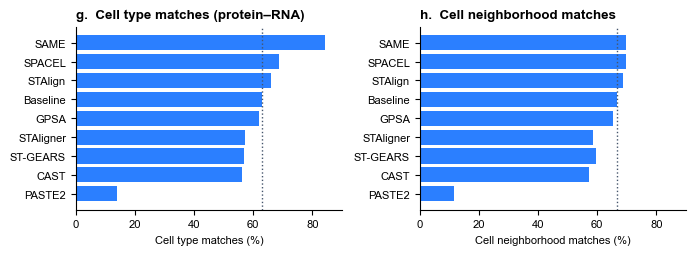

In [6]:
def bar_panel(ax, values, baseline, xlabel, xmax):
    """Horizontal bars, best method on top, with the baseline as a dotted line."""
    ax.barh(np.arange(len(values)), values.to_numpy(), height=0.8, color='#2B7FFF')
    ax.axvline(baseline, color='#45556C', linestyle=':', linewidth=1)
    ax.set_yticks(np.arange(len(values)), values.index)
    ax.set_xlim(0, xmax)
    ax.set_xlabel(xlabel)
    ax.spines[['top', 'right']].set_visible(False)


order = scores.sort_values('CT matches (%)').index
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6))
bar_panel(axes[0], scores.loc[order, 'CT matches (%)'], scores.loc['Baseline', 'CT matches (%)'], 'Cell type matches (%)', 90)
bar_panel(axes[1], scores.loc[order, 'CN matches (%)'], scores.loc['Baseline', 'CN matches (%)'],
          'Cell neighborhood matches (%)', 90)
axes[0].set_title('g.  Cell type matches (protein–RNA)', loc='left', fontweight='bold')
axes[1].set_title('h.  Cell neighborhood matches', loc='left', fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'Fig4gh_matches.svg', bbox_inches='tight')
fig.savefig(FIG_DIR / 'Fig4gh_matches.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Fig 4i — method summary

Change in cell type (CT) and cell neighborhood (CN) matches over the baseline, in percentage points.

In [7]:
CHECK = {True: '✔', False: '✘'}
TRANSFORM_COLORS = {'Elastic': '#9AE630', 'Affine': '#51A2FF', 'Rigid': '#42D3F2',
                    'Diffeomorphic': '#FFB93B', 'Space-tearing': '#FB64B6'}


def method_table(scores, methods, columns, vmin, vmax):
    """Styled summary table: method properties and change over the baseline (percentage points)."""
    t = scores.drop('Baseline').join(methods).sort_values(['Δ CT', 'Δ CN'], ascending=False)
    cols = {('Method', ''): t.index}
    for name, col in columns:
        cols[(name, '')] = t[col]
    cols[('Required inputs', 'Expression')] = t['expression'].map(CHECK)
    cols[('Required inputs', 'Cell types')] = t['cell_types'].map(CHECK)
    cols[('Δ from baseline', 'CT matches')] = t['Δ CT']
    cols[('Δ from baseline', 'CN matches')] = t['Δ CN']
    df = pd.DataFrame(cols).reset_index(drop=True)
    delta = [('Δ from baseline', 'CT matches'), ('Δ from baseline', 'CN matches')]
    inputs = [('Required inputs', 'Expression'), ('Required inputs', 'Cell types')]
    styled = (df.style
              .map(lambda v: f'color: {"#31C950" if v == CHECK[True] else "#FF2056"}', subset=inputs)
              .background_gradient(cmap='managua', vmin=vmin, vmax=vmax, subset=delta)
              .format('{:+.2f}', subset=delta)
              .set_table_styles([
                  {'selector': 'thead th', 'props': 'background:#444;color:#fff;font-weight:700;text-align:center;'},
                  {'selector': 'td', 'props': 'padding:2px 10px;text-align:center;'},
                  {'selector': 'table', 'props': 'border-collapse:separate;border-spacing:0 4px;font-family:Arial,sans-serif;'}])
              .hide(axis='index'))
    if ('Transform', '') in df.columns:
        styled = styled.map(lambda v: f'background-color: {TRANSFORM_COLORS.get(v, "#ddd")}', subset=[('Transform', '')])
    return styled


fig4i = method_table(scores, METHODS, [], vmin=-20, vmax=16)
(FIG_DIR / 'Fig4i_method_summary.html').write_text(fig4i.to_html(), encoding='utf-8')
fig4i

## 6. Fig S12 — cell neighborhoods

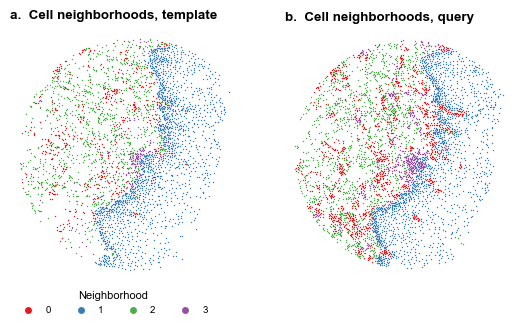

In [8]:
def neighborhood_maps(axes, xcol, ycol):
    """Cell neighborhoods on the template and query sections (initial registration)."""
    labels = sorted(set(neighborhood['template']) | set(neighborhood['query']))
    colors = dict(zip(labels, plt.get_cmap('Set1').colors))
    for ax, (name, a) in zip(axes, (('Template', template_in), ('Query', query_in))):
        lab = neighborhood[name.lower()].to_numpy()
        for l in labels:
            m = lab == l
            ax.scatter(a.obs[xcol].to_numpy()[m], a.obs[ycol].to_numpy()[m], s=1, color=colors[l], label=l, linewidths=0)
        ax.set_title(f'Cell neighborhoods, {name.lower()}', loc='left')
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.axis('off')
    axes[0].legend(title='Neighborhood', markerscale=5, frameon=False, ncol=len(labels), loc='upper left',
                   bbox_to_anchor=(0, 0), fontsize=7)


fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.4))
neighborhood_maps(axes, 'New_X', 'New_Y')
axes[0].set_title('a.  ' + axes[0].get_title(loc='left'), loc='left', fontweight='bold')
axes[1].set_title('b.  ' + axes[1].get_title(loc='left'), loc='left', fontweight='bold')
fig.savefig(FIG_DIR / 'FigS12_cell_neighborhoods.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Fig S13 — predicted RNA expression after alignment

Each assigned PCF cell takes the RNA profile (normalised to 100 counts per cell, log1p) of its MERSCOPE partner.
Columns are PCF (protein-defined) cell types; each gene is scaled to 0–1 across them, as in scanpy's
`matrixplot(standard_scale='var')`. A correct alignment puts each marker's maximum on its own cell type.

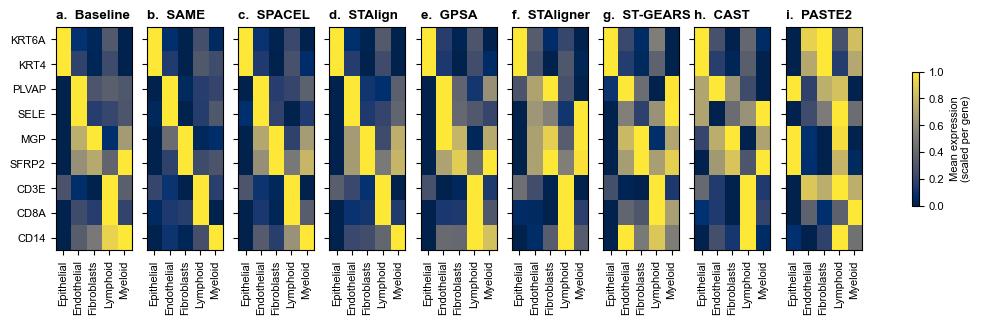

In [9]:
rna = ad.read_h5ad(EXPR_DIR / 'merSubAD.h5ad')
sc.pp.normalize_total(rna, target_sum=1e2)
sc.pp.log1p(rna)
pcf_type = ad.read_h5ad(EXPR_DIR / 'pcfSubAD.h5ad').obs.set_index('Object ID')['cell_type'].astype(str)

GENES = ['KRT6A', 'KRT4', 'PLVAP', 'SELE', 'MGP', 'SFRP2', 'CD3E', 'CD8A', 'CD14']
CELL_TYPES = ['Epithelial cells', 'Endothelial cells', 'Fibroblasts', 'Lymphoid cells', 'Myeloid cells']
expr = pd.DataFrame(rna[:, GENES].X.toarray() if hasattr(rna.X, 'toarray') else rna[:, GENES].X,
                    index=rna.obs_names.astype(str), columns=GENES)


def predicted_expression(method):
    pcf_ids, rna_ids = pairs[method]
    mean = expr.loc[rna_ids].set_axis(pcf_type.loc[pcf_ids].to_numpy()).groupby(level=0).mean().reindex(CELL_TYPES).T
    return mean.sub(mean.min(1), axis=0).div(mean.max(1) - mean.min(1), axis=0)


panels = list(METHODS.index)
fig, axes = plt.subplots(1, len(panels), figsize=(13, 2.9), sharey=True)
for k, (ax, method) in enumerate(zip(axes, panels)):
    im = ax.imshow(predicted_expression(method).to_numpy(), cmap='cividis', vmin=0, vmax=1, aspect='auto')
    ax.set_title(f'{"abcdefghi"[k]}.  {method}', loc='left', fontweight='bold')
    ax.set_xticks(range(len(CELL_TYPES)), [t.replace(' cells', '') for t in CELL_TYPES], rotation=90)
    ax.set_yticks(range(len(GENES)), GENES)
fig.colorbar(im, ax=axes, shrink=0.6, label='Mean expression\n(scaled per gene)')
fig.savefig(FIG_DIR / 'FigS13_predicted_expression.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Check against the paper

Fig 4i and the text report a baseline of 62.9% cell type matches, and improvements of +21.3 (CT) and +2.94 (CN)
percentage points for SAME and +5.9 (CT) for SPACEL.

In [10]:
PAPER_DELTA = {  # Fig 4i: (Δ CT, Δ CN)
    'SAME': (21.30, 2.94), 'SPACEL': (5.90, 3.24), 'STAlign': (3.27, 2.05), 'GPSA': (-0.97, -1.47),
    'STAligner': (-5.71, -8.20), 'ST-GEARS': (-5.90, -7.01), 'CAST': (-6.65, -9.31), 'PASTE2': (-48.81, -55.18)}
got = scores.loc[list(PAPER_DELTA), ['Δ CT', 'Δ CN']].round(2)
assert np.allclose(got.to_numpy(), list(PAPER_DELTA.values())), got
assert round(scores.loc['Baseline', 'CT matches (%)'], 1) == 62.9
print('All benchmark values match the paper.')

All benchmark values match the paper.
